# 11 · Anisotropie : le matériau orthotrope

*Notebook 11 du cours. Il suppose le notebook 3 (loi de Hooke, orthotropie) et le notebook 8 (SIMP, compliance). Le notebook 4 a déjà mis la loi orthotrope dans l'élément fini 3D.*

Une pièce imprimée en FDM n'est pas un bloc de plastique homogène : c'est un empilement de couches, chaque couche est faite de filaments collés côte à côte, et la colle entre couches est plus faible que le filament lui-même. Sa rigidité, et plus encore sa résistance, **dépendent de la direction**. La question de ce notebook est donc : que change cette anisotropie, concrètement ?
- pour la **loi de comportement** : comment la construire, la tourner, vérifier qu'elle est physiquement admissible ;
- pour la **déformée** d'une poutre selon la façon dont on l'imprime ;
- pour la **topologie optimale** ;
- et pour la **résistance**, qui n'est pas la rigidité.

**Plan.**
1. La loi orthotrope et son admissibilité ;
2. Changer de repère : tourner la rigidité ;
3. Dans l'élément fini : une poutre console imprimée à plat ou debout ;
4. La topologie optimale, isotrope contre orthotrope ;
5. Raideur et résistance : le critère de Hill (Tsai–Hill) ;
6. Bilan.

**Code promu dans `src`.** `materials.py` : `rotation_xz`, `stress_transform`, `rotate_stiffness`, `Orthotropic.rotated_stiffness`, `Strengths`, `hill_index`, `embed_plane_stress` ; `problem.py::ComplianceProblem` accepte maintenant la rigidité `C0` du matériau plein. Contrats : C-MAT-01 à 08 (C-MAT-07 et 08 sont nouveaux).

**Un avertissement sur les chiffres.** Les constantes du matériau (rapport $E_z/E_p$, résistances) sont des **valeurs de remplacement** d'ordre de grandeur pour du PLA ou du PETG ; le projet les remplacera par des mesures sur éprouvettes. Les conclusions qualitatives sont solides ; les chiffres ne sont pas ceux de votre filament.

In [1]:
import sys, math, time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "aeroptimizer").is_dir())
sys.path.insert(0, str(RACINE / "src"))
sys.path.insert(0, str(RACINE / "tests"))

from aeroptimizer.errors import MaterialError
from aeroptimizer.fem import elements as el
from aeroptimizer.fem.adjoint import solve_spd
from aeroptimizer.fem.bc import build_case
from aeroptimizer.fem.operators import StructuredFEOperator
from aeroptimizer.fem.solvers import ScipyDirect
from aeroptimizer.grid import Connectivity, Grid
from aeroptimizer.materials import (Orthotropic, Strengths, embed_plane_stress, hill_index,
                                    rotate_stiffness, rotation_xz, stress_transform)
from aeroptimizer.optim.continuation import Schedule
from aeroptimizer.optim.loop import run
from aeroptimizer.optim.oc import OC
from aeroptimizer.problem import ComplianceProblem

torch.set_default_dtype(torch.float64)       # convention du projet (CONTRACTS C-CONV-03)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
np.set_printoptions(precision=4, suppress=True, linewidth=120)

def montre(ax, rho, shape, titre=""):
    # densité 2D (x vers la droite, z vers le haut)
    ax.imshow(np.asarray(rho).reshape(shape).T, origin="lower", cmap="gray_r", vmin=0, vmax=1,
              interpolation="nearest")
    ax.set_title(titre, fontsize=9); ax.set_xticks([]); ax.set_yticks([])

## 1. La loi orthotrope et son admissibilité

Un matériau **orthotrope** a trois plans de symétrie perpendiculaires. Ses axes 1, 2, 3 sont ceux de ces plans ; on les prend ici égaux aux axes de la grille $x,y,z$, avec $z$ l'axe de construction (le projet l'impose, [FORMALISM §3.1](../../FORMALISM.md)). Il a **9 constantes indépendantes** : trois modules $E_1,E_2,E_3$, trois modules de cisaillement $G_{23},G_{13},G_{12}$ et trois coefficients de Poisson $\nu_{12},\nu_{13},\nu_{23}$ (les trois autres se déduisent de $\nu_{ij}/E_i=\nu_{ji}/E_j$). On écrit la loi sous la forme **souplesse** :

$$
\boldsymbol\varepsilon=\mathbf S\,\boldsymbol\sigma,\qquad
\mathbf S=\begin{pmatrix}
\frac{1}{E_1}&-\frac{\nu_{12}}{E_1}&-\frac{\nu_{13}}{E_1}&&&\\
&\frac{1}{E_2}&-\frac{\nu_{23}}{E_2}&&&\\
&&\frac{1}{E_3}&&&\\
&&&\frac{1}{G_{23}}&&\\
&&&&\frac{1}{G_{13}}&\\
&&&&&\frac{1}{G_{12}}
\end{pmatrix}\ \text{(symétrique)},\qquad \mathbf C_0=\mathbf S^{-1}.
$$

On a choisi la forme souplesse parce que les constantes mesurées en laboratoire (un essai de traction donne $E_i$ et $\nu_{ij}$) y apparaissent directement, une par case. Aucune case de $\mathbf C_0$ n'est une constante d'essai.

**FDM.** Les couches sont isotropes dans leur plan $(x,y)$ et différentes selon $z$ : c'est l'**isotropie transverse** d'axe $z$, un cas particulier à 5 constantes ($E_p,E_z,\nu_p,\nu_{pz},G_z$). Le module de cisaillement dans le plan est alors imposé, $G_{12}=E_p/2(1+\nu_p)$ ; c'est ce qu'applique `Orthotropic.transversely_isotropic`.

### Admissible, c'est-à-dire ?

Toute liste de 9 nombres positifs n'est pas un matériau. L'énergie de déformation $\tfrac12\boldsymbol\sigma^\top\mathbf S\boldsymbol\sigma$ doit être **strictement positive** pour toute contrainte non nulle : $\mathbf S$ doit être **définie positive**. Si ce n'est pas le cas, $\mathbf K$ perd sa définition positive et tout ce qui a été fait (Cholesky, CG, adjoint) cesse d'avoir un sens. On peut le tester par Cholesky, ce que fait le constructeur. Les conditions « par paires » que donnent les manuels, $\nu_{ij}^2<E_i/E_j$, sont **nécessaires** (ce sont les mineurs $2\times2$ de $\mathbf S$), mais **pas suffisantes** : il y a en plus une condition couplée, $1-\nu_{12}\nu_{21}-\nu_{23}\nu_{32}-\nu_{13}\nu_{31}-2\nu_{21}\nu_{32}\nu_{13}>0$. On l'illustre sur une carte.

In [2]:
# Les 9 constantes <-> S : on retrouve les constantes depuis la matrice, comme on le ferait depuis un essai.
def constantes(S):
    return dict(E1=1/S[0,0], E2=1/S[1,1], E3=1/S[2,2], G23=1/S[3,3], G13=1/S[4,4], G12=1/S[5,5],
                nu12=-S[0,1]/S[0,0], nu13=-S[0,2]/S[0,0], nu23=-S[1,2]/S[1,1])

fdm = Orthotropic.transversely_isotropic(Ep=1.0, Ez=0.75, nup=0.35, nupz=0.35, Gz=0.29)   # valeurs de remplacement
S = fdm.compliance_matrix()
print("S (FDM, Ep = 1) =\n", S.numpy())
print({k: round(float(v), 4) for k, v in constantes(S).items()})
print("aller-retour C0 @ S - I :", float((fdm.stiffness(3) @ S - torch.eye(6)).abs().max()))

S (FDM, Ep = 1) =
 [[ 1.     -0.35   -0.35    0.      0.      0.    ]
 [-0.35    1.     -0.35    0.      0.      0.    ]
 [-0.35   -0.35    1.3333  0.      0.      0.    ]
 [ 0.      0.      0.      3.4483  0.      0.    ]
 [ 0.      0.      0.      0.      3.4483  0.    ]
 [ 0.      0.      0.      0.      0.      2.7   ]]
{'E1': 1.0, 'E2': 1.0, 'E3': 0.75, 'G23': 0.29, 'G13': 0.29, 'G12': 0.3704, 'nu12': 0.35, 'nu13': 0.35, 'nu23': 0.35}
aller-retour C0 @ S - I : 2.220446049250313e-16


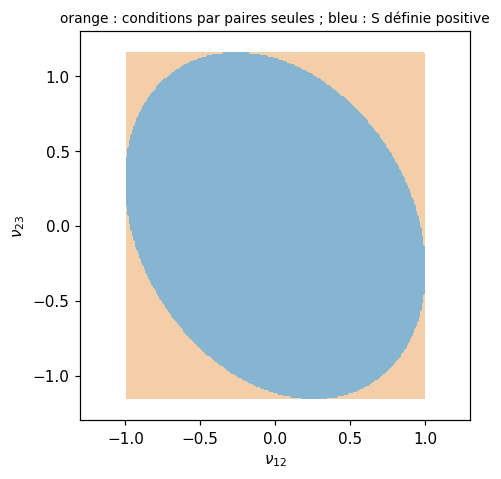

aire par paires : 0.675   aire S définie positive : 0.514   admissibles selon les paires mais refusés : 10936 points sur 45969
S ≻ 0 implique les paires ?  True


In [3]:
# Carte d'admissibilité : E = (1, 1, 0.75), nu13 = 0.3 fixé, on fait varier nu12 et nu23.
E1, E2, E3 = 1.0, 1.0, 0.75
nu13 = 0.3
grille = np.linspace(-1.3, 1.3, 261)
paires = np.zeros((grille.size, grille.size), bool)
defini = np.zeros_like(paires)
for i, n23 in enumerate(grille):
    for j, n12 in enumerate(grille):
        paires[i, j] = (n12**2 < E1/E2) and (nu13**2 < E1/E3) and (n23**2 < E2/E3)
        try:
            Orthotropic(E1, E2, E3, 0.3, 0.3, 0.3, n12, nu13, n23)
            defini[i, j] = True
        except MaterialError:
            pass
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.contourf(grille, grille, paires, levels=[0.5, 1], colors=["#f2c9a0"], alpha=0.9)
ax.contourf(grille, grille, defini, levels=[0.5, 1], colors=["#79b3d6"], alpha=0.9)
ax.set_xlabel(r"$\nu_{12}$"); ax.set_ylabel(r"$\nu_{23}$")
ax.set_title("orange : conditions par paires seules ; bleu : S définie positive", fontsize=9)
ax.set_aspect("equal"); plt.show()
print(f"aire par paires : {paires.mean():.3f}   aire S définie positive : {defini.mean():.3f}   "
      f"admissibles selon les paires mais refusés : {(paires & ~defini).sum()} points sur {paires.sum()}")
print("S ≻ 0 implique les paires ? ", bool((defini <= paires).all()))

Sur cette coupe, **la moitié seulement des points « admissibles par paires » le sont vraiment** : l'ellipse bleue est strictement contenue dans le carré orange (le programme vérifie qu'aucun point défini positif n'échappe aux conditions par paires). Les coins du carré sont des matériaux que les manuels autorisent et qui ne le sont pas. C'est pour cela que le constructeur de `Orthotropic` ne se contente pas des conditions par paires : il tente la factorisation de Cholesky de $\mathbf S$ et refuse sinon, avec un message qui nomme la condition violée (C-MAT-01).

## 2. Changer de repère : tourner la rigidité

Pourquoi tourner ? Parce que le repère du matériau (les couches) et celui de la pièce ne coïncident pas toujours : on peut imprimer une poutre couchée ou debout, ou orienter les filaments à $45^\circ$. Le projet fixe le repère du matériau sur la grille ; **tourner le matériau** est donc la façon d'étudier ces choix.

Une rotation $\mathbf R$ ($3\times3$, orthogonale) agit sur les tenseurs de contrainte et de déformation par $\boldsymbol\sigma'=\mathbf R\boldsymbol\sigma\mathbf R^\top$. Écrit en notation de Voigt ($6$ composantes), cela devient une matrice $\mathbf T$ de taille $6\times6$ : $\boldsymbol\sigma'=\mathbf T\boldsymbol\sigma$. Pour les déformations, avec les cisaillements d'ingénieur $\gamma=2\varepsilon$, on a $\boldsymbol\varepsilon'=\mathbf T^{-\top}\boldsymbol\varepsilon$ (les facteurs 2 se compensent). Comme $\boldsymbol\sigma'=\mathbf T\mathbf C\boldsymbol\varepsilon=\mathbf T\mathbf C\mathbf T^\top\boldsymbol\varepsilon'$, la rigidité du matériau tourné est

$$
\boxed{\mathbf C'=\mathbf T\,\mathbf C\,\mathbf T^{\top}}.
$$

On construit $\mathbf T$ **colonne par colonne** en appliquant $\mathbf R(\cdot)\mathbf R^\top$ aux six tenseurs de base : pas de formule à 36 termes à recopier (et à se tromper). La rotation utilisée ici tourne $x$ vers $z$ d'un angle $\theta$ (sens trigonométrique avec $x$ à droite et $z$ en haut), $y$ restant fixe : c'est celle des problèmes 2D du projet.

On la valide contre **deux oracles**, indépendants de l'implémentation : (i) la rotation directe du tenseur d'ordre 4, $C'_{ijkl}=R_{ia}R_{jb}R_{kc}R_{ld}C_{abcd}$, par `einsum` ; (ii) la formule classique du module dans une direction hors axes :

$$
\frac{1}{E_x(\theta)}=\frac{\cos^4\theta}{E_1}+\Big(\frac{1}{G_{13}}-\frac{2\nu_{13}}{E_1}\Big)\sin^2\theta\cos^2\theta+\frac{\sin^4\theta}{E_3}.
$$

In [4]:
ortho = Orthotropic(E1=1.0, E2=0.8, E3=0.6, G23=0.2, G13=0.25, G12=0.3, nu12=0.3, nu13=0.25, nu23=0.2)
C = ortho.stiffness(3)

# (i) oracle : rotation du tenseur d'ordre 4, index par index
V = [(0, 0), (1, 1), (2, 2), (1, 2), (0, 2), (0, 1)]
def tourne_ordre4(C, R):
    C4 = np.zeros((3, 3, 3, 3))
    for a, (i, j) in enumerate(V):
        for b, (k, l) in enumerate(V):
            for ii, jj in {(i, j), (j, i)}:
                for kk, ll in {(k, l), (l, k)}:
                    C4[ii, jj, kk, ll] = C[a, b].item()
    Rn = R.numpy()
    C4r = np.einsum("ia,jb,kc,ld,abcd->ijkl", Rn, Rn, Rn, Rn, C4)
    return np.array([[C4r[i, j, k, l] for (k, l) in V] for (i, j) in V])

def E_formule(theta, m):
    c, s = math.cos(theta), math.sin(theta)
    return 1 / (c**4/m.E1 + (1/m.G13 - 2*m.nu13/m.E1)*s*s*c*c + s**4/m.E3)

print(f"{'theta':>7} {'écart tenseur ordre 4':>24} {'Ex tourné':>11} {'formule':>9}")
for deg in (0, 15, 30, 45, 90, -60):
    th = math.radians(deg); R = rotation_xz(th)
    Cr = rotate_stiffness(C, R)
    ecart = np.abs(Cr.numpy() - tourne_ordre4(C, R)).max()
    Ex = 1 / torch.linalg.inv(Cr)[0, 0].item()
    print(f"{deg:>6}° {ecart:>24.1e} {Ex:>11.6f} {E_formule(th, ortho):>9.6f}")

  theta    écart tenseur ordre 4   Ex tourné   formule
     0°                  0.0e+00    1.000000  1.000000
    15°                  2.2e-16    0.911792  0.911792
    30°                  1.1e-16    0.755906  0.755906
    45°                  1.1e-16    0.648649  0.648649
    90°                  6.2e-33    0.600000  0.600000
   -60°                  1.1e-16    0.603774  0.603774


Les deux oracles sont retrouvés à la précision machine. D'autres propriétés doivent tenir, et se testent sans oracle :

- **groupe** : tourner de $a$ puis de $b$ revient à tourner de $a+b$ ;
- **isotrope** : un matériau isotrope est inchangé par toute rotation ;
- **$90^\circ$** : $x$ et $z$ sont échangés, donc $E_1\leftrightarrow E_3$ ;
- **énergie** : $\boldsymbol\varepsilon^\top\mathbf C\boldsymbol\varepsilon$ est la même dans les deux repères (c'est le contrôle que $\boldsymbol\varepsilon'=\mathbf T^{-\top}\boldsymbol\varepsilon$ est la bonne loi pour les déformations).

In [5]:
a, b = 0.4, 0.9
print("groupe R(a)R(b) - R(a+b)      :", float((rotation_xz(a) @ rotation_xz(b) - rotation_xz(a + b)).abs().max()))
iso = Orthotropic.isotropic(2.0, 0.3).stiffness(3)
print("isotrope invariant (écart max) :", float((rotate_stiffness(iso, rotation_xz(0.77)) - iso).abs().max()))
Sr = torch.linalg.inv(rotate_stiffness(C, rotation_xz(math.pi/2)))
print("90° : E1, E3 deviennent        :", round(1/Sr[0,0].item(), 6), round(1/Sr[2,2].item(), 6), "(attendu 0.6, 1.0)")
T = stress_transform(rotation_xz(a))
eps = torch.tensor([0.3, -0.1, 0.2, 0.05, -0.4, 0.15])
eps_r = torch.linalg.inv(T).T @ eps
print("énergie avant / après          :", float(eps @ C @ eps), float(eps_r @ rotate_stiffness(C, rotation_xz(a)) @ eps_r))
print("T^{-1} = T de -a (R orthogonale) :", float((torch.linalg.inv(T) - stress_transform(rotation_xz(-a))).abs().max()))

groupe R(a)R(b) - R(a+b)      : 5.551115123125783e-17
isotrope invariant (écart max) : 1.3322676295501878e-15
90° : E1, E3 deviennent        : 0.6 1.0 (attendu 0.6, 1.0)
énergie avant / après          : 0.18630281899109793 0.18630281899109793
T^{-1} = T de -a (R orthogonale) : 1.1102230246251565e-16


### À quoi ressemble l'anisotropie ?

Le module $E_x(\theta)$ dans une direction à l'angle $\theta$ de l'axe 1 se représente en coordonnées polaires (rayon $=E$). Un matériau isotrope donne un cercle. On compare :
- **FDM** : $E_z/E_p=0{,}75$, valeur de remplacement ; la figure est un ovale allongé selon $x$, de $E=0{,}75$ (selon $z$) à $E=1$ (selon $x$) ;
- un **composite unidirectionnel** (fibres de carbone) : $E_1/E_3=10$, très allongé.

Hors axes il apparaît aussi un phénomène que l'isotrope ne connaît pas : le **couplage traction–cisaillement**. Tirer à $30^\circ$ des axes d'un matériau orthotrope produit une déformation de cisaillement dans le repère de la pièce. En termes de matrice, $\mathbf C'$ n'est plus « orthotrope » : sa case $(xx,xz)$ cesse d'être nulle.

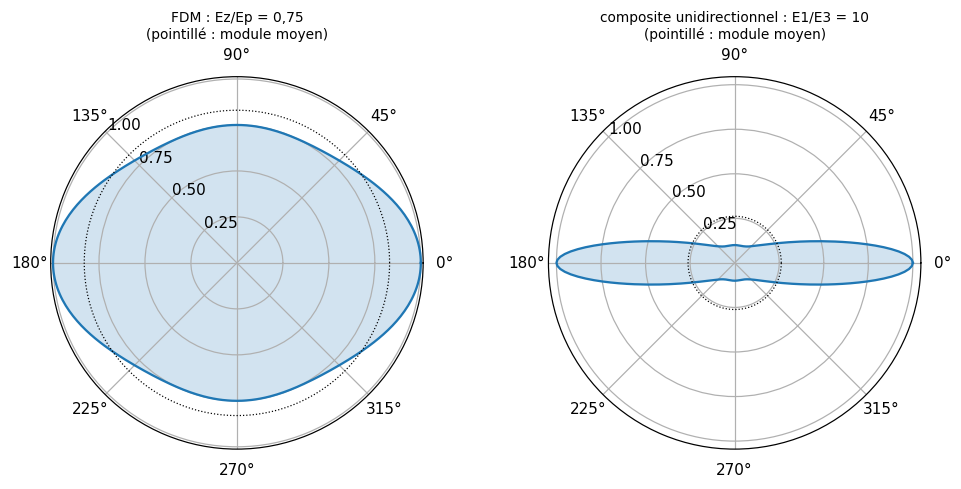

composite tourné de 30° — C'(xx,xz) = 0.2886   (0 pour le matériau aligné : 0.0 )
traction sigma_xx = 1 : (eps_xx, eps_zz, gamma_xz) = [ 4.825 -1.875 -5.716]


In [6]:
comp = Orthotropic(E1=1.0, E2=0.1, E3=0.1, G23=0.04, G13=0.05, G12=0.05, nu12=0.3, nu13=0.3, nu23=0.4)
th = np.linspace(0, 2*np.pi, 361)
def courbe(m):
    return np.array([1 / torch.linalg.inv(rotate_stiffness(torch.linalg.inv(m.compliance_matrix()),
                                                           rotation_xz(t)))[0, 0].item() for t in th])
fig, axs = plt.subplots(1, 2, figsize=(9.2, 4.4), subplot_kw={"projection": "polar"})
for ax, (nom, m) in zip(axs, [("FDM : Ez/Ep = 0,75", fdm), ("composite unidirectionnel : E1/E3 = 10", comp)]):
    E = courbe(m); ax.plot(th, E); ax.fill(th, E, alpha=0.2)
    ax.plot(th, np.full_like(th, E.mean()), "k:", lw=0.8)
    ax.set_title(f"{nom}\n(pointillé : module moyen)", fontsize=9); ax.set_rticks([0.25, 0.5, 0.75, 1.0]); ax.set_rlabel_position(135)
plt.tight_layout(); plt.show()

# couplage traction-cisaillement : sigma_xx = 1 seul, matériau tourné de 30°
Cr2 = comp.rotated_stiffness(rotation_xz(math.radians(30)), 2)
eps = torch.linalg.solve(Cr2, torch.tensor([1.0, 0.0, 0.0]))
print("composite tourné de 30° — C'(xx,xz) =", round(Cr2[0, 2].item(), 4), "  (0 pour le matériau aligné :",
      round(comp.stiffness(2)[0, 2].item(), 4), ")")
print("traction sigma_xx = 1 : (eps_xx, eps_zz, gamma_xz) =", eps.numpy().round(3))

## 3. Dans l'élément fini : une poutre console imprimée à plat ou debout

Le matériau entre dans le code par une seule matrice, $\mathbf C_0$, qui fabrique $\mathbf K_e^0$ (notebook 4). Rien d'autre ne change : le solveur, l'adjoint et le SIMP voient la même chose ([FORMALISM §3.2](../../FORMALISM.md) : un facteur scalaire $s(\bar\rho)$ multiplie tout $\mathbf C_0$, l'anisotropie est celle du plein). Il suffit de passer `C0` au problème.

**La poutre console.** Une poutre de longueur $L=100$ et de hauteur $h=10$ (contraintes planes, épaisseur 1), encastrée à gauche, chargée en bout. Imprimée **à plat** : son axe est le long des couches, donc la rigidité en flexion met en jeu $E_p$. Imprimée **debout** : son axe est selon $z$, donc $E_z$. Dans le plan 2D $(x,z)$, « debout » est le matériau tourné de $90^\circ$.

Euler–Bernoulli prédit une flèche $\delta=PL^3/3EI$ proportionnelle à $1/E$ de l'axe ; le cisaillement ajoute $PL/\kappa GA$ (Timoshenko, $\kappa\approx5/6$). Le rapport des travaux $\mathbf f^\top\mathbf u$ doit donc valoir $E_z/E_p$ à quelques pour cent. On le mesure avec trois maillages.

In [7]:
def travail(C0, shape):
    g = Grid(shape, (1.0, 1.0)); fixed, load, _ = build_case("cantilever", g)
    op = StructuredFEOperator(g, Connectivity(g, 2), el.elasticity_ke0(2, g.h, C0), 2, fixed)
    f = load.assemble(torch.ones(shape))
    u = solve_spd(op, torch.ones(g.n_elems), f, ScipyDirect())
    return float(f @ u)          # = P x flèche moyenne en bout (P = 1)

Rup = rotation_xz(math.pi / 2)
plat, debout = fdm.stiffness(2), fdm.rotated_stiffness(Rup, 2)
isoC = Orthotropic.isotropic(1.0, 0.3).stiffness(2)

L, h = 100.0, 10.0; I = h**3 / 12
print(f"{'cas':>8} {'FE (100x10)':>12} {'EB seul':>9} {'EB + cisaillement':>18}")
for nom, C0, E, G in [("iso", isoC, 1.0, 1/(2*1.3)), ("plat", plat, 1.0, 0.29), ("debout", debout, 0.75, 0.29)]:
    eb = L**3 / (3*E*I); tim = eb + L / (5/6 * G * h)
    print(f"{nom:>8} {travail(C0, (100, 10)):>12.1f} {eb:>9.1f} {tim:>18.1f}")
print()
for shape in [(50, 5), (100, 10), (200, 20)]:
    print(f"maillage {str(shape):>9} : travail(plat)/travail(debout) = {travail(plat, shape)/travail(debout, shape):.4f}   (E_z/E_p = 0.75)")

     cas  FE (100x10)   EB seul  EB + cisaillement
     iso       4003.2    4000.0             4031.2
    plat       4016.5    4000.0             4041.4
  debout       5338.0    5333.3             5374.7

maillage   (50, 5) : travail(plat)/travail(debout) = 0.7546   (E_z/E_p = 0.75)
maillage (100, 10) : travail(plat)/travail(debout) = 0.7524   (E_z/E_p = 0.75)
maillage (200, 20) : travail(plat)/travail(debout) = 0.7519   (E_z/E_p = 0.75)


La flèche suit $1/E$ de l'axe de la poutre. Imprimer debout une pièce dont les efforts sont dirigés selon son axe long la rend environ $1/0{,}75$ fois plus souple. Avec le rapport FDM réel c'est un effet de $25\,\%$, pas un facteur 10.

**Poutre composite : et si le matériau est tourné ?** Avec un matériau très anisotrope ($E_1/E_3=10$), on tourne les « fibres » de $0$ à $90^\circ$. L'estimation Euler–Bernoulli avec le module hors axe, $\delta\approx PL^3/3E_x(\theta)I$, doit rester proche. Elle ignore le cisaillement, le couplage traction–cisaillement et l'effet de l'encastrement : l'écart mesure ce qu'elle néglige.

 angle  travail FE   4000/Ex   écart
    0°        4233      4000    5.8%
   15°        8176      8512   -3.9%
   30°       18055     19300   -6.5%
   45°       28829     30400   -5.2%
   60°       36286     37300   -2.7%
   75°       39424     39688   -0.7%
   90°       40029     40000    0.1%


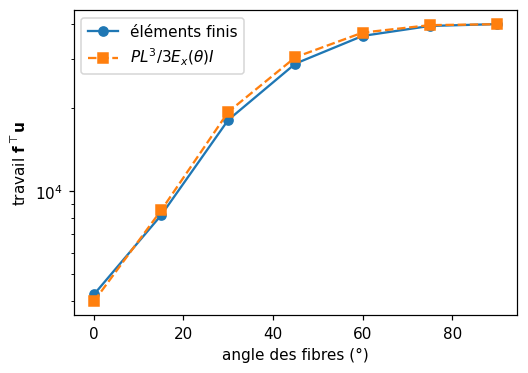

In [8]:
print(f"{'angle':>6} {'travail FE':>11} {'4000/Ex':>9} {'écart':>7}")
fe, est, angles = [], [], list(range(0, 91, 15))
for deg in angles:
    Cr = comp.rotated_stiffness(rotation_xz(math.radians(deg)), 2)
    Ex = 1 / torch.linalg.inv(Cr)[0, 0].item()
    w = travail(Cr, (100, 10)); e = L**3 / (3 * I) / Ex      # Euler-Bernoulli avec le module hors axe
    fe.append(w); est.append(e)
    print(f"{deg:>5}° {w:>11.0f} {e:>9.0f} {100*(w/e-1):>6.1f}%")
fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.semilogy(angles, fe, "o-", label="éléments finis"); ax.semilogy(angles, est, "s--", label=r"$PL^3/3E_x(\theta)I$")
ax.set_xlabel("angle des fibres (°)"); ax.set_ylabel("travail $\\mathbf{f}^\\top\\mathbf{u}$"); ax.legend(); plt.show()

L'estimation tient à $7\,\%$ près sur toute la plage, alors que la flèche varie d'un facteur $10$. À $0^\circ$ elle est **trop basse** de $6\,\%$ : elle oublie le cisaillement, qui compte quand $G_{13}$ est vingt fois plus faible que $E_1$. Entre $15^\circ$ et $60^\circ$ elle est **trop haute** : la poutre réelle est plus raide que prévu (de $3$ à $7\,\%$), vraisemblablement parce que l'encastrement empêche la section racine de se cisailler librement, alors que la formule du module hors axe suppose un état de contrainte uniforme (explication non vérifiée ici). À $90^\circ$ l'accord est à $0{,}1\,\%$ (seul $E_3$ intervient).

## 4. La topologie optimale, isotrope contre orthotrope

On optimise maintenant la forme. Sur la poutre MBB de la leçon 8 (60×20, fraction volumique $0{,}5$, filtre $R=3$, continuation en $\beta$ de 1 à 16, OC), on change seulement `C0`. Deux questions distinctes :

1. **Combien vaut l'orientation d'impression ?** On compare la même forme optimisée dans différents matériaux. C'est l'effet *du matériau* à forme donnée.
2. **Combien gagne-t-on à adapter la forme à l'anisotropie ?** On compare, dans un matériau donné, la forme optimisée *pour lui* à la forme optimisée en isotrope. C'est le *gain de la topologie anisotrope*.

**Un garde-fou.** L'optimisation topologique a des minima locaux (leçon 8) : deux départs différents donnent des compliances qui diffèrent d'un ou deux pour cent. Avant de lire un écart, il faut savoir si l'on est au-dessus de ce bruit. On mesure d'abord le bruit sur le cas isotrope avec 6 départs aléatoires.

In [9]:
SHAPE = (60, 20)
def optimise(C0, x0=None, it=250):
    pb = ComplianceProblem("mbb", SHAPE, volfrac=0.5, R=3.0, C0=C0)
    sch = Schedule(p=(3.0, 3.0), beta=(1.0, 16.0), beta_s=(1.0, 1.0), every=50)
    return pb, run(pb, OC(move=0.2), sch, max_iter=it, tol=1e-3, x0=x0)

def compliance_de(C0, x):
    # évalue la forme x (variables de conception) dans le matériau C0, projection finale beta = 16
    pb = ComplianceProblem("mbb", SHAPE, volfrac=0.5, R=3.0, C0=C0, beta=16.0)
    return float(pb.evaluate(torch.from_numpy(x)).terms["C"])

rng = np.random.default_rng(0)
t0 = time.time()
bruit = []
for graine in range(6):
    x0 = np.clip(0.5 + 0.1 * rng.standard_normal(SHAPE[0] * SHAPE[1]), 0.05, 0.95)
    pb, r = optimise(isoC, x0=x0); bruit.append(compliance_de(isoC, r.x))
bruit = np.array(bruit)
print("compliances (isotrope, 6 départs) :", bruit.round(1))
print(f"moyenne {bruit.mean():.1f}, écart-type {bruit.std():.2f} ({100*bruit.std()/bruit.mean():.2f} %), "
      f"étendue {100*(bruit.max()-bruit.min())/bruit.mean():.2f} %    ({time.time()-t0:.0f} s)")

compliances (isotrope, 6 départs) : [193.7 195.4 193.9 193.6 193.5 194.8]
moyenne 194.1, écart-type 0.71 (0.36 %), étendue 0.98 %    (15 s)


In [10]:
# Sept matériaux : isotrope, FDM plat / debout (Ez/Ep = 0.75), très anisotrope (Ez/Ep = 0.1) à 0°, -45°, +45°, debout
def ti(rat):
    return Orthotropic.transversely_isotropic(Ep=1.0, Ez=rat, nup=0.3, nupz=0.3, Gz=0.385 * (1 + rat) / 2)
def tourne(rat, deg):
    return ti(rat).rotated_stiffness(rotation_xz(math.radians(deg)), 2)

materiaux = {
    "isotrope":          isoC,
    "FDM plat":          tourne(0.75, 0),
    "FDM debout":        tourne(0.75, 90),
    "aniso 0.1 à 0°":    tourne(0.1, 0),
    "aniso 0.1 à -45°":  tourne(0.1, -45),
    "aniso 0.1 à +45°":  tourne(0.1, 45),
    "aniso 0.1 debout":  tourne(0.1, 90),
}
formes = {}
for nom, C0 in materiaux.items():
    pb, r = optimise(C0); formes[nom] = r.x

noms = list(materiaux)
M = np.array([[compliance_de(materiaux[mat], formes[forme]) for mat in noms] for forme in noms])   # lignes : formes
print("compliance de la forme (ligne) évaluée dans le matériau (colonne)")
print(f"{'':>18}" + "".join(f"{n[:14]:>16}" for n in noms))
for i, n in enumerate(noms):
    print(f"{'forme '+n:>18}" + "".join(f"{M[i,j]:>16.1f}" for j in range(len(noms))))

compliance de la forme (ligne) évaluée dans le matériau (colonne)
                          isotrope        FDM plat      FDM debout  aniso 0.1 à 0°  aniso 0.1 à -4  aniso 0.1 à +4  aniso 0.1 debo
    forme isotrope           193.2           201.9           249.6           311.6           677.0           896.4          1599.7
    forme FDM plat           194.0           202.6           250.7           308.7           673.3           904.5          1609.3
  forme FDM debout           195.4           204.2           252.6           313.1           688.4           903.3          1619.1
forme aniso 0.1 à 0°           219.2           225.7           286.4           293.1           690.6          1045.0          1921.5
forme aniso 0.1 à -45°           213.4           223.4           275.3           334.6           606.0          1149.6          1726.7
forme aniso 0.1 à +45°           270.7           290.9           341.7           582.8          1198.6           854.0          1956.4
forme a

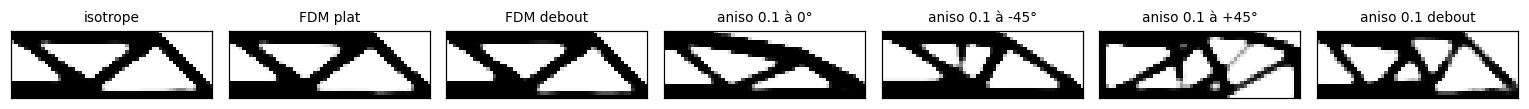

Gain de la topologie adaptée : (forme isotrope dans le matériau) / (forme optimisée pour lui) - 1
            isotrope :  +0.0 %
            FDM plat :  -0.3 %
          FDM debout :  -1.2 %
      aniso 0.1 à 0° :  +6.3 %
    aniso 0.1 à -45° : +11.7 %
    aniso 0.1 à +45° :  +5.0 %
    aniso 0.1 debout :  +0.3 %


In [11]:
fig, axs = plt.subplots(1, len(noms), figsize=(2.0 * len(noms), 1.9))
for ax, n in zip(axs, noms):
    pb = ComplianceProblem("mbb", SHAPE, volfrac=0.5, R=3.0, beta=16.0)
    montre(ax, pb.rho_bar(torch.from_numpy(formes[n])).detach().numpy(), SHAPE, n)
plt.tight_layout(); plt.show()

print("Gain de la topologie adaptée : (forme isotrope dans le matériau) / (forme optimisée pour lui) - 1")
for j, n in enumerate(noms):
    print(f"  {n:>18} : {100*(M[0, j]/M[j, j]-1):+5.1f} %")

**Ce que ces nombres disent.** Lire la matrice par colonne : on fixe le matériau et on compare les formes ; la valeur de la diagonale devrait être la plus basse de la colonne, à bruit près (le bruit mesuré : écart-type $0{,}4\,\%$, étendue $1\,\%$).

- **L'orientation compte beaucoup plus que l'adaptation de la forme.** Avec le rapport FDM ($0{,}75$), la forme est environ $25\,\%$ plus souple imprimée debout qu'à plat (de $202$ à $250$) ; avec un rapport de $0{,}1$, la même comparaison donne un facteur $5$ (de $293$ à $1595$). Une pièce dont les efforts suivent $x$ s'imprime à plat.
- **Au rapport FDM, adapter la forme ne rapporte rien de mesurable** : dans les colonnes « FDM plat » et « FDM debout », la forme isotrope est aussi bonne que la forme « adaptée » (écart de $-0{,}3$ et $-1{,}2\,\%$, signe défavorable à l'adaptation, c'est-à-dire des minima locaux différents et non un effet du matériau). On peut optimiser en isotrope si le rapport reste proche de $1$.
- **Quand l'anisotropie est forte ($0{,}1$), la forme adaptée gagne de $5$ à $12\,\%$ selon l'orientation**, très au-dessus du bruit, sauf pour la pièce debout ($0{,}3\,\%$) où la forme isotrope est déjà adaptée : l'axe raide est alors vertical et suit la charge. Le gain est maximal à $-45^\circ$ : la fibre suit la bielle comprimée de la MBB, qui descend de la charge vers l'appui.
- **Une forme optimisée pour une orientation et imprimée dans l'autre est fortement pénalisée.** La forme de $+45^\circ$ dans le matériau à $-45^\circ$ donne $1199$ au lieu de $606$ (facteur $2$) ; la forme de « aniso debout » imprimée à plat donne $413$ au lieu de $293$ ($+41\,\%$).

Le **gain de la topologie anisotrope** n'est donc pas ce qui fera gagner le projet à rapport FDM ; le choix de l'**orientation d'impression** est le levier. Reste la question de la résistance.

## 5. Raideur et résistance : le critère de Hill

Tout ce qui précède mesure la **raideur** (la compliance). Une pièce peut être raide et se rompre très tôt : la raideur dit combien elle se déforme, la résistance dit à partir de quelle contrainte elle casse. En FDM l'écart est grand : le **module** dans le sens $z$ vaut typiquement $70$ à $90\,\%$ de celui dans le plan, mais la **résistance** interlaminaire n'en vaut que $40$ à $60\,\%$, car elle dépend de la soudure entre couches et non du filament.

Pour un matériau orthotrope, le critère le plus simple est celui de **Hill (1948)**, appelé Tsai–Hill dans la littérature des composites : une forme quadratique des contraintes **dans les axes du matériau**,

$$
F=\mathcal{F}(\sigma_2-\sigma_3)^2+\mathcal{G}(\sigma_3-\sigma_1)^2+\mathcal{H}(\sigma_1-\sigma_2)^2+\Big(\tfrac{\tau_{23}}{S_{23}}\Big)^2+\Big(\tfrac{\tau_{13}}{S_{13}}\Big)^2+\Big(\tfrac{\tau_{12}}{S_{12}}\Big)^2,
$$

avec $2\mathcal{F}=\tfrac{1}{Y^2}+\tfrac{1}{Z^2}-\tfrac{1}{X^2}$ (et permutations circulaires pour $\mathcal{G}$, $\mathcal{H}$), où $X,Y,Z$ sont les résistances en traction selon les trois axes et $S_{ij}$ les résistances en cisaillement. **$F<1$ : sain ; $F=1$ : rupture.** Comme $F$ est quadratique, $\sqrt{F}$ est proportionnel à la charge : $1/\sqrt{F_{\max}}$ est le facteur de charge à la rupture.

Trois propriétés se vérifient (contrat C-MAT-08) :
- une traction égale à $X$, $Y$ ou $Z$, ou un cisaillement égal à $S_{ij}$, donne $F=1$ ;
- avec des résistances isotropes ($X=Y=Z=\sigma_y$, $S=\sigma_y/\sqrt3$), $F$ est le **von Mises** au carré divisé par $\sigma_y^2$ ;
- une contrainte hydrostatique donne $F=0$. C'est une **limite** du critère : un polymère réel est sensible à la pression, ce que ne représente pas Hill.

In [12]:
st = Strengths(X=45.0, Y=45.0, Z=25.0, S23=25.0, S13=25.0, S12=30.0)   # valeurs de remplacement (MPa)
z6 = torch.zeros(6)
for k, (nom, valeur) in enumerate(zip("X Y Z S23 S13 S12".split(), (45, 45, 25, 25, 25, 30))):
    s = z6.clone(); s[k] = valeur
    print(f"contrainte = résistance {nom:>3} : F = {float(hill_index(s, st)):.12f}")

sy = 30.0; isoS = Strengths(sy, sy, sy, sy/3**0.5, sy/3**0.5, sy/3**0.5)
sig = torch.randn(5, 6, generator=torch.Generator().manual_seed(0)) * 10
s1, s2, s3, t23, t13, t12 = sig.unbind(-1)
vm2 = 0.5*((s1-s2)**2 + (s2-s3)**2 + (s3-s1)**2) + 3*(t23**2 + t13**2 + t12**2)
print("Hill isotrope − von Mises²/σy² :", float((hill_index(sig, isoS) - vm2/sy**2).abs().max()))
print("contrainte hydrostatique (5,5,5,0,0,0) :", float(hill_index(torch.tensor([5., 5., 5., 0, 0, 0]), isoS)))
try:
    Strengths(X=45.0, Y=45.0, Z=0.0, S23=1.0, S13=1.0, S12=1.0)
except MaterialError as e:
    print("MaterialError :", e)

contrainte = résistance   X : F = 1.000000000000
contrainte = résistance   Y : F = 1.000000000000
contrainte = résistance   Z : F = 1.000000000000
contrainte = résistance S23 : F = 1.000000000000
contrainte = résistance S13 : F = 1.000000000000
contrainte = résistance S12 : F = 1.000000000000
Hill isotrope − von Mises²/σy² : 8.881784197001252e-16
contrainte hydrostatique (5,5,5,0,0,0) : 0.0
MaterialError : strength Z must be > 0, got 0.0


### Récupérer les contraintes dans la poutre MBB

Le critère veut les contraintes, que l'élément fini ne donne pas directement. Pour un élément $e$ plein : $\boldsymbol\varepsilon_e=\mathbf B(\mathbf 0)\,\mathbf u_e$ au centre, puis $\boldsymbol\sigma_e=\mathbf C_0\boldsymbol\varepsilon_e$, **dans le repère de la grille**. Il faut ensuite les ramener dans les **axes du matériau** (là où sont définies les résistances) : $\boldsymbol\sigma_{\text{mat}}=\mathbf T(\mathbf R^\top)\,\boldsymbol\sigma_{\text{grille}}$ après avoir mis la contrainte plane $(xx,zz,xz)$ dans les 6 composantes (`embed_plane_stress`).

On valide d'abord la récupération sur un champ de déplacement **affine**, pour lequel la contrainte est connue exactement et vaut la même chose dans tous les éléments.

In [13]:
def contraintes_elements(pb, u):
    # contrainte plane (xx, zz, xz) au centre de chaque élément, repère de la grille ; B au centre = moyenne des points de Gauss
    B = el.strain_displacement(el.shape_grads(2, pb.grid.h)).mean(0)
    return (u[pb.op.edof] @ B.T) @ pb.C0.T

# test de patch : u_x = a x + b z, u_z = c x + d z  =>  eps = (a, d, b + c), sigma = C0 eps partout
pb_p = ComplianceProblem("cantilever", (8, 4), volfrac=1.0, R=1.0, C0=tourne(0.3, 30))
nodes = torch.stack(torch.meshgrid(torch.arange(9.), torch.arange(5.), indexing="ij"), -1).reshape(-1, 2)
a_, b_, c_, d_ = 0.01, 0.02, -0.015, 0.005
u_aff = torch.stack([a_*nodes[:, 0] + b_*nodes[:, 1], c_*nodes[:, 0] + d_*nodes[:, 1]], -1).reshape(-1)
sig_p = contraintes_elements(pb_p, u_aff)
attendu = pb_p.C0 @ torch.tensor([a_, d_, b_ + c_])
print("patch test (écart max sur tous les éléments) :", float((sig_p - attendu).abs().max()))

patch test (écart max sur tous les éléments) : 1.5612511283791264e-17


In [14]:
def indice_sqrtF(C0, R, x, st):
    pb = ComplianceProblem("mbb", SHAPE, volfrac=0.5, R=3.0, C0=C0, beta=16.0)
    e = pb.evaluate(torch.from_numpy(x)); rb = pb.rho_bar(torch.from_numpy(x)).detach()
    s6 = embed_plane_stress(contraintes_elements(pb, e.state.detach()))
    sm = s6 @ stress_transform(R.T).T                      # grille -> axes du matériau
    return rb.numpy(), hill_index(sm, st).sqrt().numpy(), float(e.terms["C"])

R_plat, R_debout = torch.eye(3), rotation_xz(math.pi / 2)
res = {}
for nom, R in [("FDM plat", R_plat), ("FDM debout", R_debout)]:
    rb, si, Cc = indice_sqrtF(materiaux[nom], R, formes[nom], st)
    sol = rb > 0.5
    res[nom] = dict(rb=rb, si=si, C=Cc, p99=np.percentile(si[sol], 99), p95=np.percentile(si[sol], 95), max=si[sol].max())
    print(f"{nom:>10} : compliance {Cc:6.1f}   sqrt(F) p95 {res[nom]['p95']:.4f}  p99 {res[nom]['p99']:.4f}  max {res[nom]['max']:.4f}")

rk = res["FDM debout"]["C"] / res["FDM plat"]["C"]
rr = res["FDM debout"]["p99"] / res["FDM plat"]["p99"]
print(f"\nimprimer debout plutôt qu'à plat : compliance × {rk:.2f}   charge à la rupture × {1/rr:.2f}  (p99)")

  FDM plat : compliance  202.6   sqrt(F) p95 0.0196  p99 0.0256  max 0.0486
FDM debout : compliance  252.6   sqrt(F) p95 0.0356  p99 0.0409  max 0.0568

imprimer debout plutôt qu'à plat : compliance × 1.25   charge à la rupture × 0.63  (p99)


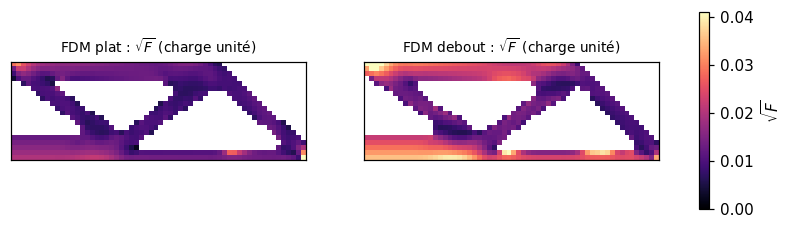

  FDM plat : p99 de sqrt(F), résistances Hill FDM = 0.0256, résistances isotropes (45) = 0.0261  -> rapport 0.98
FDM debout : p99 de sqrt(F), résistances Hill FDM = 0.0409, résistances isotropes (45) = 0.0237  -> rapport 1.72


In [15]:
fig, axs = plt.subplots(1, 2, figsize=(9.5, 2.9))
vmax = max(res[n]["p99"] for n in res)
for ax, n in zip(axs, res):
    im = np.where(res[n]["rb"] > 0.5, res[n]["si"], np.nan).reshape(SHAPE).T
    h = ax.imshow(im, origin="lower", cmap="magma", vmin=0, vmax=vmax, interpolation="nearest")
    ax.set_title(f"{n} : $\\sqrt{{F}}$ (charge unité)", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(h, ax=axs, shrink=0.8, label=r"$\sqrt{F}$"); plt.show()

# Que dirait une analyse isotrope des résistances (toutes égales à 45) ?
iso45 = Strengths(45.0, 45.0, 45.0, 45.0 / 3**0.5, 45.0 / 3**0.5, 45.0 / 3**0.5)
for nom, R in [("FDM plat", R_plat), ("FDM debout", R_debout)]:
    rb, si_iso, _ = indice_sqrtF(materiaux[nom], R, formes[nom], iso45)
    sol = rb > 0.5
    print(f"{nom:>10} : p99 de sqrt(F), résistances Hill FDM = {res[nom]['p99']:.4f}, résistances isotropes (45) = {np.percentile(si_iso[sol], 99):.4f}"
          f"  -> rapport {res[nom]['p99'] / np.percentile(si_iso[sol], 99):.2f}")

**Lecture.** Imprimer debout plutôt qu'à plat rend la pièce $25\,\%$ plus souple et fait chuter la charge à la rupture de $37\,\%$ (facteur $0{,}63$) : la perte de résistance est plus sévère que la perte de raideur. La raison se lit dans le dernier calcul : à plat, les contraintes principales sont dans le plan des couches ($X=Y=45$) et une analyse avec des résistances isotropes à $45$ donne **la même** valeur (rapport $0{,}98$) ; debout, l'axe $x$ de la grille est l'axe faible $Z$ du matériau, et les semelles (où la contrainte est selon $x$, voir la carte) sont les zones critiques : la charge sollicite l'axe faible $Z$ et les cisaillements $S_{13}$ du matériau, et l'analyse isotrope **sous-estime l'indice d'un facteur $1{,}7$**. Optimiser la compliance ne contrôle pas ces contraintes.

**Précautions de lecture.**
- On utilise le $99^e$ centile de $\sqrt{F}$ sur les éléments pleins plutôt que le maximum : le maximum est piloté par les singularités (le nœud chargé, le nœud d'appui, les angles rentrants), qui dépendent du maillage.
- Les contraintes sont celles d'un modèle élastique linéaire à éléments Q1 : elles sont discontinues d'un élément à l'autre et grossières sur les contours.
- Hill est symétrique traction/compression et aveugle à la pression. Un critère FDM sérieux distingue la traction interlaminaire (le maillon faible) de la compression, et traite la rupture par **délaminage**, qui est un phénomène d'interface.
- Les résistances de ce notebook sont des valeurs de remplacement.

Contraindre la résistance dans l'optimisation (contrainte de contrainte, agrégation $p$-norme) est un problème difficile et hors du périmètre de la v1 ; le projet retient la compliance et note ici que la **pièce finale devra être vérifiée** a posteriori.

## Bilan

| Constat | Où c'est dans le code |
|---|---|
| 9 constantes $\Rightarrow$ $\mathbf S$ $\Rightarrow$ $\mathbf C_0$ ; admissible $\Leftrightarrow$ $\mathbf S\succ0$ (Cholesky) ; les conditions par paires sont nécessaires mais non suffisantes | `Orthotropic`, C-MAT-01 à 06 |
| Rotation : $\mathbf C'=\mathbf T\mathbf C\mathbf T^\top$, $\mathbf T$ construit sur la base de Voigt ; validé contre le tenseur d'ordre 4 et la formule de $E_x(\theta)$ à $10^{-12}$ | `rotation_xz`, `stress_transform`, `rotate_stiffness`, C-MAT-07 |
| Hors axes : couplage traction–cisaillement ; à $90^\circ$ : $E_1\leftrightarrow E_3$ | §2 |
| Poutre console : le rapport de flèches suit $E_z/E_p$ à quelques % | `ComplianceProblem(C0=...)`, `test_compliance` |
| Orientation d'impression : levier de rigidité de $25\,\%$ (FDM) à un facteur 5 (très anisotrope) ; debout au lieu d'à plat : charge à la rupture $\times0{,}63$ | §4, §5 |
| Adapter la forme à l'anisotropie : indiscernable du bruit au rapport FDM, de $5$ à $12\,\%$ pour un rapport $0{,}1$ (sauf debout) ; bruit des minima locaux : $0{,}4\,\%$ | §4 |
| Résistance $\neq$ raideur : indice de Hill, récupération des contraintes validée par patch test | `hill_index`, `Strengths`, C-MAT-08 |

**Limites à retenir.**
- **Le repère du matériau est celui de la grille** (contrat du projet). Une pièce courbe, ou dont les filaments suivent la forme, n'est pas représentée.
- **L'interpolation SIMP multiplie $\mathbf C_0$ par un scalaire** ($s(\bar\rho)$) : à densité intermédiaire, l'anisotropie du matériau plein est conservée telle quelle. Rien ne dit qu'un matériau « à demi-plein » imprimé se comporte ainsi (taux de remplissage, motifs d'infill) : c'est un modèle.
- **Les valeurs sont des valeurs de remplacement.** Un essai de traction sur éprouvettes imprimées à plat, sur le côté et debout donne $E_p$, $E_z$, les résistances, et valide le modèle.
- **L'effet de l'anisotropie sur la topologie est mesuré sur un seul cas** (la MBB, un seul chargement) : les chiffres ne se transposent pas tels quels au bras de drone.
- **Hill n'est pas une garantie de rupture** : voir §5.

**Pour expérimenter.** (i) Au §3, passez le rapport $E_z/E_p$ de $0{,}75$ à $0{,}3$ : le rapport des travaux suit-il ? (ii) Au §4, rejouez le tableau avec le cas `cantilever` (changez `"mbb"` dans `optimise`) : l'orientation optimale change-t-elle ? (iii) Au §4, ajoutez un angle de $-30^\circ$ ou $-60^\circ$ : où est le meilleur gain, et pourquoi pas exactement à $45^\circ$ ? (iv) Au §5, abaissez $Z$ à $15$ : comment bouge l'écart entre plat et debout ? (v) Au §1, fixez $\nu_{13}=0{,}6$ et regardez la carte : l'aire admissible rétrécit-elle ?

*Suite : leçon 12 (surplomb et auto-support). Voir le [plan des leçons](README.md).*